In [1]:
#!/usr/bin/env python3
import os
import pickle
import subprocess
import sys
from typing import Any

import numpy as np
import pandas as pd
from scipy.interpolate import interp1d


SCAM_PATH = os.path.join(os.path.expanduser("~"), "Github", "SCAM")
EYE_FILTER_CSV = os.path.join(SCAM_PATH, "config", "Mouse_transmittance.csv")

In [27]:
eye_filter = np.loadtxt(EYE_FILTER_CSV, delimiter=",")
filter_wavelengths = eye_filter[:, 0]
filter_transmitance  = eye_filter[:, 1]

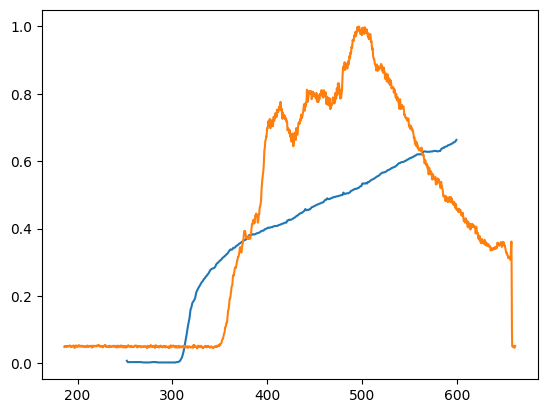

In [31]:
plt.plot(filter_wavelengths,filter_transmitance/100.0)
plt.plot(spec_nm,example_spectral_reading/np.max(example_spectral_reading))


In [21]:
scan_dict

{'wavelengths': array([186.06072998, 186.41267789, 186.76456181, ..., 660.37952225,
        660.66446331, 660.94937982], shape=(1516,)),
 'intensity': array([511., 534., 530., ..., 490., 522., 536.], shape=(1516,)),
 'dark_corrected': array([511., 534., 530., ..., 490., 522., 536.], shape=(1516,)),
 'metadata': {'integration_time_ms': 50,
  'serial_number': 'ST03283\x00',
  'dark_correction_applied': False},
 'success': True,
 'motor_pan': 0,
 'motor_tilt': 18,
 'ts': '20260308_141425'}

In [12]:
npy_file='./scan_data/scan_iter0_0_pan0_tilt18.npy'

In [13]:
scan_dict = np.load(npy_file, allow_pickle=True).item()

In [15]:
example_spectral_reading = scan_dict['intensity']

In [22]:
spec_nm = scan_dict['wavelengths']

In [16]:
mouse_eye_filter=load_mouse_eye_filter()

In [18]:
import matplotlib.pyplot as plt

In [24]:
mouse_eye_filter.shape

(300,)

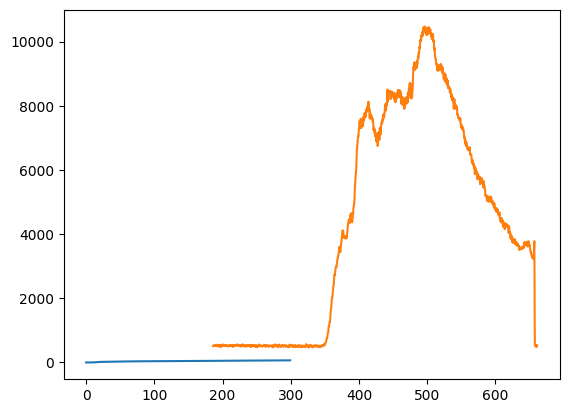

In [23]:
plt.plot(mouse_eye_filter[:mouse_eye_filter)
plt.plot(spec_nm,example_spectral_reading)

## Stepwise Spectral Pipeline Demo (Single Raw Reading)
This section shows one `.npy` reading through: raw spectrum -> mouse optic filtering -> AUC with S/M/rod kernels -> M/S ratio.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


from spec_data_utils import (
    add_interpolated_and_filtered_spectrum,
    load_pr_kernels_300_599,
    UNIVERSAL_WAVELENGTHS,
)

In [2]:
raw_npy = os.path.expanduser('~/Github/SCAM/one_scam_data/ONE_SCAM_20260308_141257/scan_data/scan_iter0_0_pan0_tilt18.npy')
scan = np.load(raw_npy, allow_pickle=True).item()

wavelength = np.asarray(scan['wavelengths'], dtype=np.float64)
spectrum = np.asarray(scan['intensity'], dtype=np.float64)

df_one = pd.DataFrame([{
    'wavelength': wavelength,
    'spectrum': spectrum,
    'adjusted_corrected_spectrum': spectrum,
}])

In [3]:
df_one = add_interpolated_and_filtered_spectrum(df_one, spectrum_col='adjusted_corrected_spectrum')

interp = df_one.loc[0, 'interpolated_spectrum']
filt = df_one.loc[0, 'filtered_spectrum']

kernels = load_pr_kernels_300_599()
x = kernels['wavelength']
s_curve = filt * kernels['scone']
m_curve = filt * kernels['mcone']
r_curve = filt * kernels['rod']

auc_s = np.trapezoid(s_curve, x=x)
auc_m = np.trapezoid(m_curve, x=x)
auc_r = np.trapezoid(r_curve, x=x)
ratio_m_over_s = auc_m / auc_s if auc_s != 0 else np.nan

print('Raw file:', raw_npy)
print('AUC_S:', auc_s)
print('AUC_M:', auc_m)
print('AUC_rod:', auc_r)
print('AUC_M / AUC_S:', ratio_m_over_s)

Raw file: /Users/dengyuyao/Github/SCAM/one_scam_data/ONE_SCAM_20260308_141257/scan_data/scan_iter0_0_pan0_tilt18.npy
AUC_S: 55431.89431658988
AUC_M: 452919.46738078375
AUC_rod: 438044.5490864472
AUC_M / AUC_S: 8.170737676652559


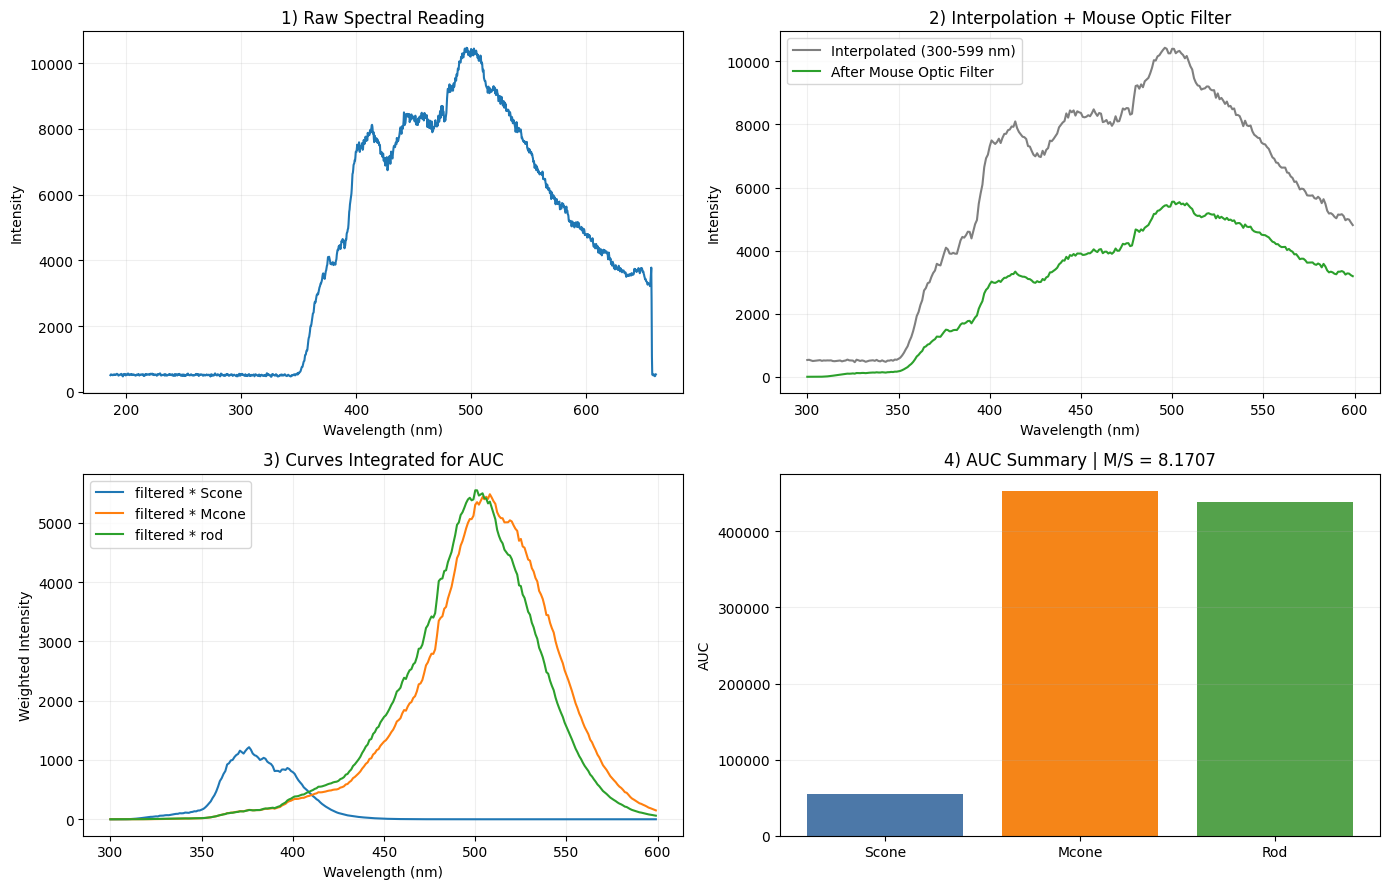

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# 1) Raw spectrum
axes[0, 0].plot(wavelength, spectrum, color='tab:blue', lw=1.5)
axes[0, 0].set_title('1) Raw Spectral Reading')
axes[0, 0].set_xlabel('Wavelength (nm)')
axes[0, 0].set_ylabel('Intensity')
axes[0, 0].grid(alpha=0.2)

# 2) Interpolated + optic-filtered
axes[0, 1].plot(UNIVERSAL_WAVELENGTHS, interp, label='Interpolated (300-599 nm)', color='tab:gray')
axes[0, 1].plot(UNIVERSAL_WAVELENGTHS, filt, label='After Mouse Optic Filter', color='tab:green')
axes[0, 1].set_title('2) Interpolation + Mouse Optic Filter')
axes[0, 1].set_xlabel('Wavelength (nm)')
axes[0, 1].set_ylabel('Intensity')
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.2)

# 3) Weighted curves for AUC
axes[1, 0].plot(x, s_curve, label='filtered * Scone', lw=1.5)
axes[1, 0].plot(x, m_curve, label='filtered * Mcone', lw=1.5)
axes[1, 0].plot(x, r_curve, label='filtered * rod', lw=1.5)
axes[1, 0].set_title('3) Curves Integrated for AUC')
axes[1, 0].set_xlabel('Wavelength (nm)')
axes[1, 0].set_ylabel('Weighted Intensity')
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.2)

# 4) AUC summary + ratio
labels = ['Scone', 'Mcone', 'Rod']
vals = [auc_s, auc_m, auc_r]
axes[1, 1].bar(labels, vals, color=['#4C78A8', '#F58518', '#54A24B'])
axes[1, 1].set_title(f'4) AUC Summary | M/S = {ratio_m_over_s:.4f}')
axes[1, 1].set_ylabel('AUC')
axes[1, 1].grid(axis='y', alpha=0.2)

plt.tight_layout()
plt.show()